Steps in RiSCAN Pro:

- Select all scan positions
- Right click -> Find reflectors.
- Make sure to select the correct reflector shape (at QFL cilinder 50)
- Select all TPL
- Right click -> export
- Export as a csv in *Project Coordinate System*

Type of coordinate system:

- Global coordinate system in a known CRS
- RiSCAN Project coordinate system. This is a local coordinate system but the north points towards the true north.
- Plot coordinates system, Local coordinate system with the origin at the SW corner and the plot sides perfectly aligned with north-south and east-west. 

# Utility functions

In [1]:
from pathlib import Path

import numpy as np
import polars as pl
import polars_ds as pds
from great_tables import GT, html
from plotnine import *
from plotnine import (
    aes,
    coord_fixed,
    geom_histogram,
    geom_point,
    geom_text,
    ggplot,
    labs,
    scale_x_continuous,
    scale_y_continuous,
    theme,
    theme_bw,
    theme_set,
)
from polars import col as c
from pyprojroot import here
from scipy.cluster.hierarchy import fcluster, linkage

theme_set(theme_bw())

In [2]:
def round_nearest(expr, distance):
    """
    Round column values to the nearest multiple of a given distance.

    Cast to int if distance is an integer, otherwise cast to float with appropriate precision.

    Args:
        expr: A Polars expression representing the column to be rounded.
        distance: The distance to which the values should be rounded.

    Returns:
        A Polars expression with the rounded values.
    """
    # Round to the nearest multiple of distance, by dividing by distance, rounding, and multiplying back by distance
    expr_nearest = expr.truediv(distance).round().mul(distance)
    # Make the visualization pretties
    is_integer = isinstance(distance, int)
    n_digits = len(str(distance).split(".")[1]) if not is_integer else 0
    return expr_nearest.round(n_digits).cast(pl.Int64 if is_integer else pl.Float64)

In [3]:
def add_label(refl, rounding=1):
    """
    Add a label to the reflector positions based on their x and y coordinates.
    The label is a string that combines the rounded x and y coordinates, separated by an underscore.

    Args:
        refl (DataFrame): A Polars DataFrame containing reflector positions with 'x' and 'y' columns.
        rounding (float): The coordinates will be rounded to the nearest multiple of `rounding`.
    """
    return refl.with_columns(
        label=pl.concat_str(
            [
                round_nearest(c.x, rounding).cast(pl.String),
                round_nearest(c.y, rounding).cast(pl.String),
            ],
            separator="_",
        )
    )


In [4]:
def plot_refl(refl, point_extra_aes=None, point_kwargs=None, grid_distance=10):
    plot = ggplot(
        refl,
        aes(
            x="x",
            y="y",
        ),
    )
    # If there is a grid add it below the reflectors
    has_grid = ("x_grid" in refl.columns) and ("y_grid" in refl.columns)
    if has_grid:
        plot = (
            plot
            + geom_point(aes(x="x_grid", y="y_grid"), color="red", shape="X")
            + labs(title="Reflector positions on perfect grid")
        )

    plot = plot + geom_point(
        size=2, **(point_kwargs or {"alpha": 0.6}), mapping=(point_extra_aes or aes())
    )
    # Add labels if available
    has_labels = "label" in refl.columns
    if has_labels:
        plot = plot + geom_text(aes(label="label"), size=8, nudge_y=2, color="grey")
    # Add titles and labels
    return (
        plot
        + labs(
            title="Reflector positions"
            if not has_grid
            else "Reflector positions on perfect grid",
            x="X [m]",
            y="Y [m]",
        )
        + coord_fixed()
        + scale_x_continuous(
            breaks=lambda lims: np.arange(
                np.floor(lims[0] / grid_distance) * grid_distance,
                np.ceil(lims[1] / grid_distance) * grid_distance + grid_distance / 2,
                grid_distance,
            )
        )
        + scale_y_continuous(
            breaks=lambda lims: np.arange(
                np.floor(lims[0] / grid_distance) * grid_distance,
                np.ceil(lims[1] / grid_distance) * grid_distance + grid_distance / 2,
                grid_distance,
            )
        )
    )

# Load reflectors positions

In [5]:
def load_refl_all(folder_tpl: Path):
    """
    Load all reflector positions from CSV files in the specified folder.
    """
    reflectors_raw = pl.concat(
        [
            pl.read_csv(f).with_columns(pl.lit(f.stem).alias("file_name"))
            for f in folder_tpl.glob("*.csv")
        ]
    )
    reflectors = (
        reflectors_raw.select(
            c.Name,
            x=pl.col("X[m]").str.strip_chars(" ").cast(pl.Float64),
            y=pl.col("Y[m]").str.strip_chars(" ").cast(pl.Float64),
            z=pl.col("Z[m]").str.strip_chars(" ").cast(pl.Float64),
            scan_pos=c.file_name.str.extract(r"ScanPos(\d{3})").cast(pl.Int64),
        )
        .sort(["x", "y", "scan_pos"])
        .with_row_index("reflector_id")
    )
    return reflectors


Let's load the raw reflectors positions as extracted from RiSCAN Pro.

The reflectors are extracted for each scan positions, so a reflector that is visible from multiple scan positions will be extracted multiple times. 
The data in the in the "RiSCAN Pro Project coordinate system".

In [6]:
refl_all = load_refl_all(here("reflector_positions_part2"))
refl_all

reflector_id,Name,x,y,z,scan_pos
u32,str,f64,f64,f64,i64
0,"""TP_006""",0.662,0.198,100.645,4
1,"""TP_005""",0.662,0.212,100.649,2
2,"""TP_007""",0.664,0.193,100.654,6
3,"""TP_004""",0.665,0.194,100.658,7
4,"""TP_004""",0.671,0.195,100.647,5
…,…,…,…,…,…
195,"""TP_006""",99.853,-23.433,99.739,21
196,"""TP_003""",99.855,-23.451,99.737,20
197,"""TP_004""",104.068,-14.352,99.716,22


## Aggregate reflectors from different scan positions

In [7]:
def agg_reflectors(refl_all, max_deviation=0.5):
    """
    Aggregate reflectors based on their proximity in the x and y coordinates.

    Uses hierarchical clustering to group reflectors that are within a specified maximum deviation distance from each other.

    """
    pts = refl_all.select("x", "y").to_numpy()
    labels = fcluster(
        linkage(pts, method="complete"), t=max_deviation, criterion="distance"
    )
    return (
        refl_all.with_columns(cluster=labels)
        .group_by("cluster")
        .agg(
            x=c.x.mean(),
            y=c.y.mean(),
            x_std=c.x.std(),
            y_std=c.y.std(),
            n_scan_pos=pl.len(),
            ids=c.reflector_id,
        )
    )

In [8]:
refl_agg = agg_reflectors(refl_all).pipe(add_label)
refl_agg

cluster,x,y,x_std,y_std,n_scan_pos,ids,label
i32,f64,f64,f64,f64,u32,list[u32],str
44,74.189,8.453,null,null,1,[144],"""74_8"""
13,36.2036,6.22,0.011887,0.007314,5,"[51, 52, … 55]","""36_6"""
39,49.51025,10.76475,0.011442,0.009359,4,"[74, 75, … 77]","""50_11"""
4,0.678286,0.197714,0.030043,0.008321,7,"[0, 1, … 6]","""1_0"""
43,67.7735,2.490833,0.003782,0.00407,6,"[123, 124, … 128]","""68_2"""
…,…,…,…,…,…,…,…
28,64.3252,-28.9984,0.009418,0.006189,5,"[118, 119, … 122]","""64_-29"""
16,18.295667,14.245667,0.010017,0.006429,3,"[23, 24, 25]","""18_14"""
45,72.792667,-10.6025,0.007967,0.009138,6,"[137, 138, … 142]","""73_-11"""


# Transform to plot coordinates system

## Translation

Assume reflector closest to the origin is the origin. In other words that scan position 1 is on the origin.

In [9]:
def get_origin_reflector(refl_agg) -> tuple[float, float]:
    """
    Get the origin point from the aggregated reflector positions.

    The origin point is determined by finding the reflector closest to the origin (0, 0) in the aggregated reflector positions.

    Args:
        refl_agg: A Polars DataFrame containing aggregated reflector positions.
    Returns:
        A tuple containing the x and y coordinates of the origin point.
    """
    origin = refl_agg.filter(c.x.pow(2) + c.y.pow(2) == c.x.pow(2) + c.y.pow(2).min())
    return (origin["x"][0], origin["y"][0])

In [10]:
origin = get_origin_reflector(refl_agg)
origin

(0.6782857142857143, 0.1977142857142857)

In [11]:
def traslate_to_origin(refl, origin: tuple[float, float]):
    return refl.with_columns(
        x=c.x - origin[0],
        y=c.y - origin[1],
    )

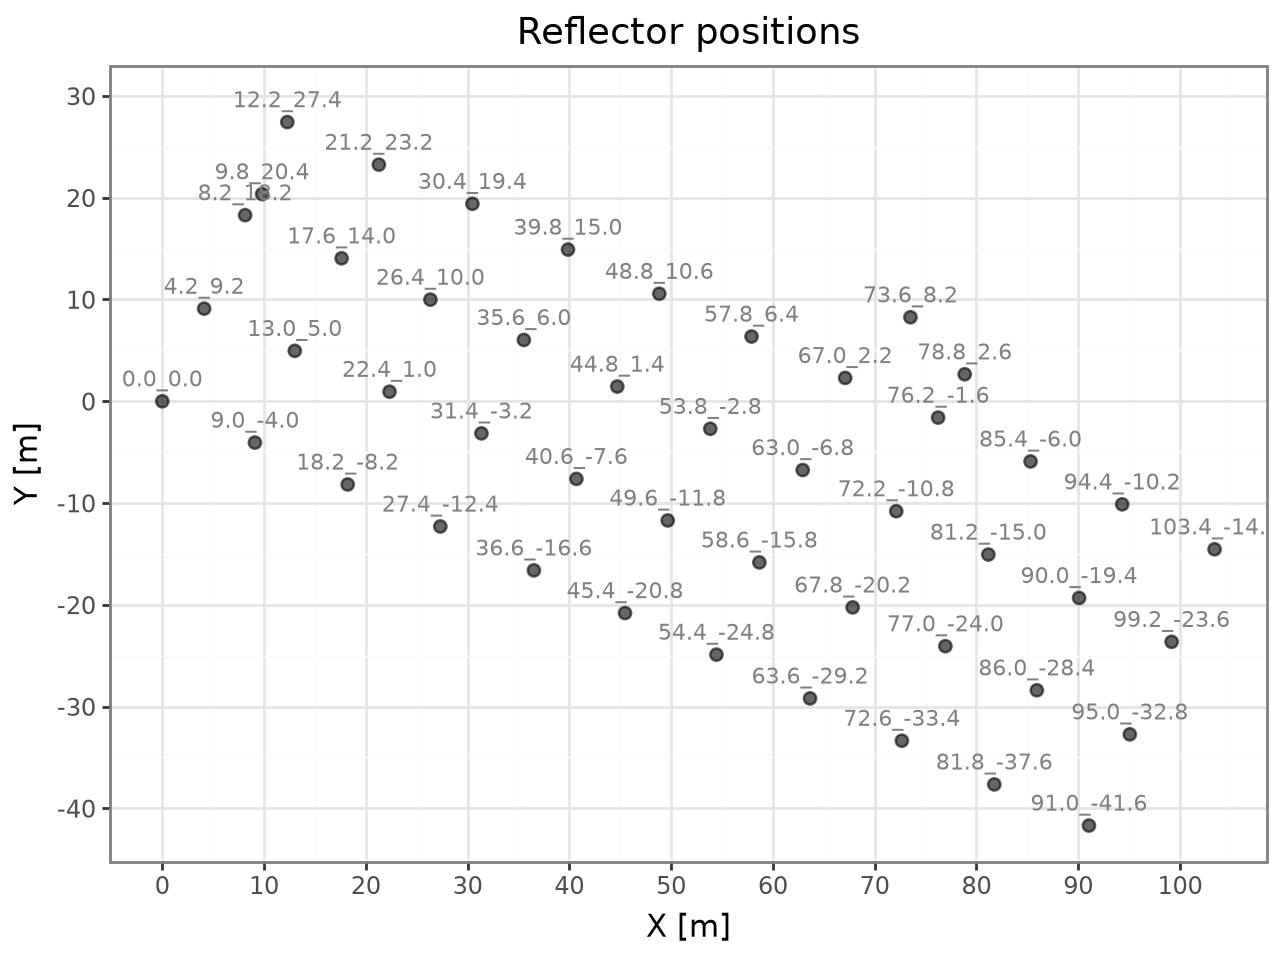

In [12]:
refl_trans = traslate_to_origin(refl_agg, origin=origin).pipe(add_label, rounding=0.2)
plot_refl(refl_trans)

## Rotation

In [ ]:
def rotate_on_origin(refl, theta: float):
    theta = np.deg2rad(theta)
    cos_theta = np.cos(theta)
    sin_theta = np.sin(theta)
    return refl.with_columns(
        x=c.x * cos_theta + c.y * sin_theta,
        y=-c.x * sin_theta + c.y * cos_theta,
    )

#### First rotation

To help identify the bottom row (which is used as the reference for the directionality), first do a rough rotation of 23 degrees and then adjust it.

In [14]:
first_rot_angle = -23.5

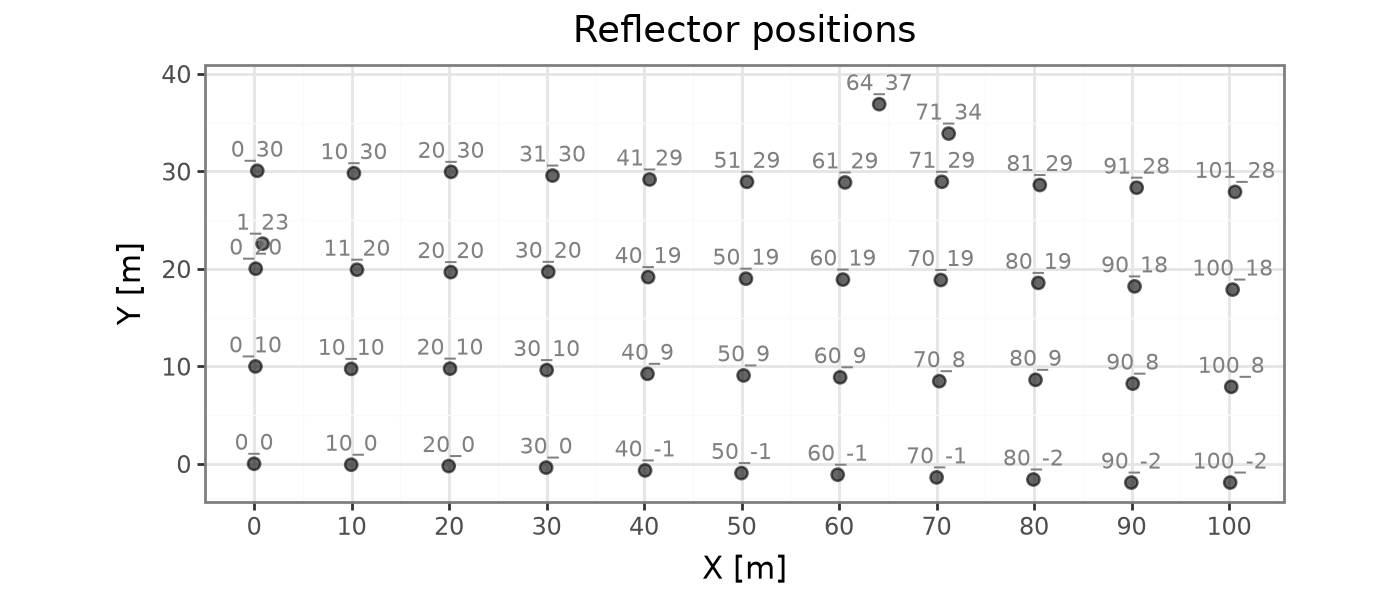

In [15]:
refl_first_rot = rotate_on_origin(refl_trans, theta=first_rot_angle).pipe(add_label)
plot_refl(refl_first_rot) + theme(figure_size=(7, 3))

#### Select the bottom row

Select the row where the y coordinate is within 5 m of 0.

In [16]:
bottom_row = refl_first_rot.filter(round_nearest(c.y, 5) == 0).sort(c.x)
bottom_row

cluster,x,y,x_std,y_std,n_scan_pos,ids,label
i32,f64,f64,f64,f64,u32,list[u32],str
4,0.0,0.0,0.030043,0.008321,7,"[0, 1, … 6]","""0_0"""
3,9.965092,-0.096987,0.012029,0.006099,5,"[13, 14, … 17]","""10_0"""
7,19.961986,-0.233963,0.007146,0.00582,6,"[26, 27, … 31]","""20_0"""
8,29.958598,-0.389016,null,null,1,[43],"""30_0"""
36,40.107501,-0.680311,null,null,1,[56],"""40_-1"""
…,…,…,…,…,…,…,…
33,59.859941,-1.120121,0.007014,0.005225,5,"[94, 95, … 98]","""60_-1"""
28,70.009967,-1.395443,0.009418,0.006189,5,"[118, 119, … 122]","""70_-1"""
31,79.936873,-1.610538,null,null,1,[143],"""80_-2"""


#### Fit linear regression

Find the true direction by fitting a linear regression to the bottom row

In [17]:
direction_slope = (
    bottom_row.select(pds.lin_reg(c.x, target=c.y, add_bias=False)).item().item()
)

final_rot_angle = np.rad2deg(np.arctan(direction_slope)).item()
print(
    f"Final rotation angle: {final_rot_angle:.3f} degrees, from a slope of {direction_slope:.3f}. \nTotal rotation of {first_rot_angle + final_rot_angle:.3f} degrees ({first_rot_angle:.3f} + {final_rot_angle:.3f})."
)

Final rotation angle: -1.119 degrees, from a slope of -0.020. 
Total rotation of -24.619 degrees (-23.500 + -1.119).


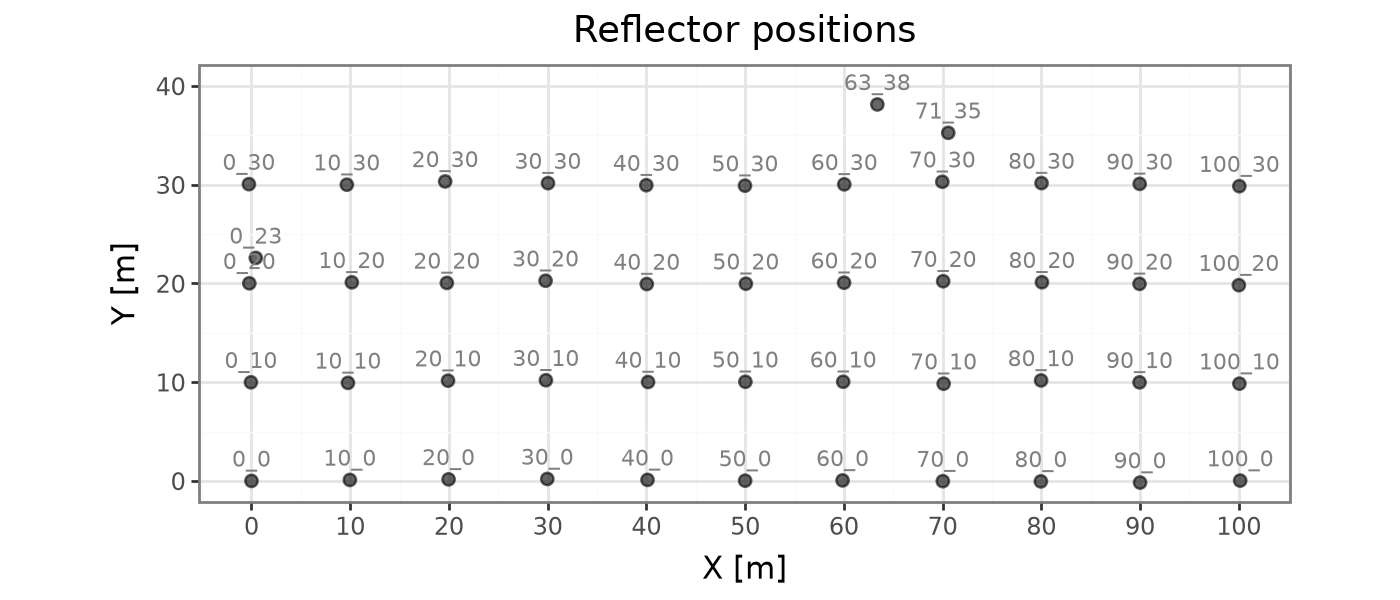

In [18]:
refl_final_rot = rotate_on_origin(refl_first_rot, theta=final_rot_angle).pipe(add_label)
plot_refl(refl_final_rot) + theme(figure_size=(7, 3))

# Compare with perfect grid

#### Generate the perfect grid

In [19]:
def get_perfect_grid(n_rows, n_cols, spacing):
    return (
        pl.DataFrame({"x": range(0, n_cols * spacing, spacing)})
        .join(pl.DataFrame({"y": range(0, n_rows * spacing, spacing)}), how="cross")
        .pipe(add_label)
    )

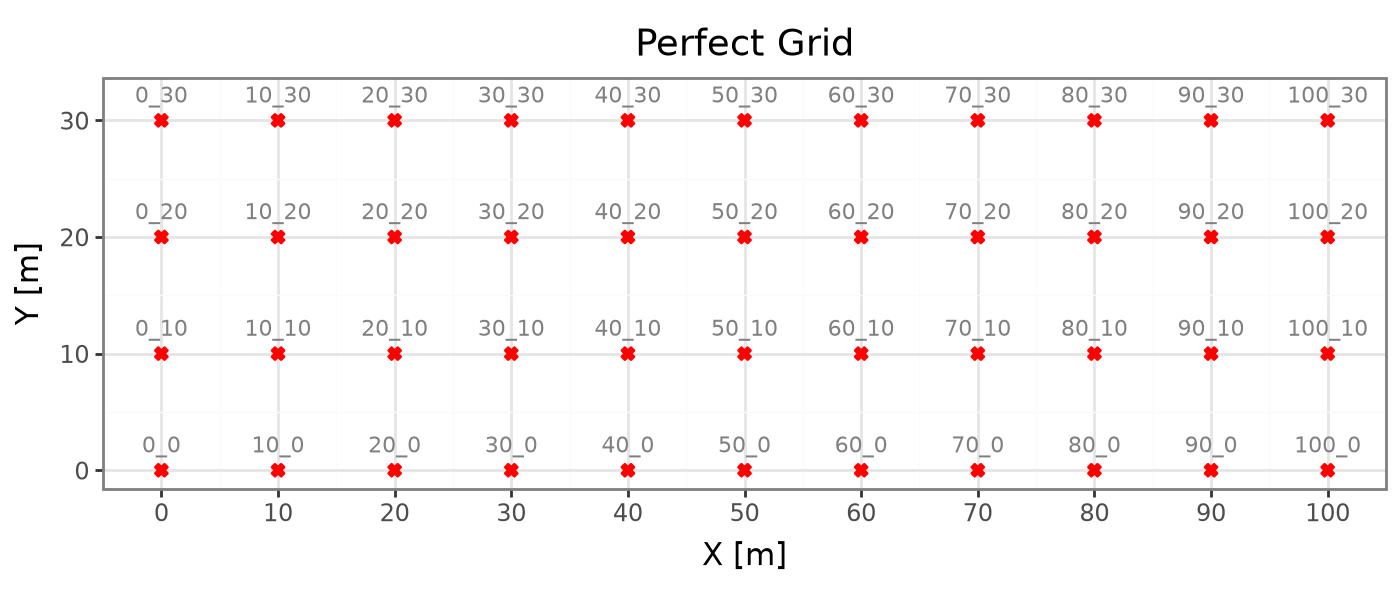

In [20]:
perfect_grid = get_perfect_grid(n_cols=11, n_rows=4, spacing=10)
plot_refl(perfect_grid, point_kwargs={"color": "red", "shape": "X"}) + labs(
    title="Perfect Grid"
) + theme(figure_size=(7, 3))

#### Join with perfect grid and remove spurious reflectors.

RiSCAN Pro can detect spurious reflectors, so we need to remove them. For now we do this by excluding points that are outside the `max_deviation` threshold from the perfect grid.

In [21]:
def join_grid(refl_final_rot, perfect_grid, max_deviation=3):
    # Important, make sure that labels have the correct rounding.
    return (
        refl_final_rot.pipe(add_label, max_deviation)
        .join(
            perfect_grid.pipe(add_label, max_deviation),
            on="label",
            how="right",
            suffix="_grid",
        )
        .with_columns(
            x_corr=c.x_grid - c.x,
            y_corr=c.y_grid - c.y,
        )
        .with_columns(distance=(c.x_corr.pow(2) + c.y_corr.pow(2)).sqrt())
        .with_columns(distance_bin=round_nearest(c.distance, 0.1))
    )

In [22]:
refl_df = join_grid(refl_final_rot, perfect_grid, max_deviation=2)
# Test all labels has exactly one match in the perfect grid
assert(refl_df.group_by("label").agg(pl.len()).select(c.len.eq(1).all()).item())

refl_df

cluster,x,y,x_std,y_std,n_scan_pos,ids,x_grid,y_grid,label,x_corr,y_corr,distance,distance_bin
i32,f64,f64,f64,f64,u32,list[u32],i64,i64,str,f64,f64,f64,f64
4,0.0,0.0,0.030043,0.008321,7,"[0, 1, … 6]",0,0,"""0_0""",0.0,0.0,0.0,0.0
1,-0.054132,9.987074,0.006364,0.010607,2,"[7, 8]",0,10,"""0_10""",0.054132,0.012926,0.055654,0.1
9,-0.220228,20.012728,0.011165,0.006583,4,"[9, 10, … 12]",0,20,"""0_20""",0.220228,-0.012728,0.220595,0.2
12,-0.2606,30.053277,0.01044,0.005508,3,"[19, 20, 21]",0,30,"""0_30""",0.2606,-0.053277,0.26599,0.3
3,9.965086,0.097626,0.012029,0.006099,5,"[13, 14, … 17]",10,0,"""10_0""",0.034914,-0.097626,0.103681,0.1
…,…,…,…,…,…,…,…,…,…,…,…,…,…
20,89.959996,30.084285,0.002517,0.004933,3,"[189, 190, 191]",90,30,"""90_30""",0.040004,-0.084285,0.093297,0.1
26,100.140197,0.030572,0.004163,0.005568,3,"[186, 187, 188]",100,0,"""100_0""",-0.140197,-0.030572,0.143492,0.1
27,100.058969,9.849817,0.008485,0.007778,2,"[192, 193]",100,10,"""100_10""",-0.058969,0.150183,0.161345,0.2


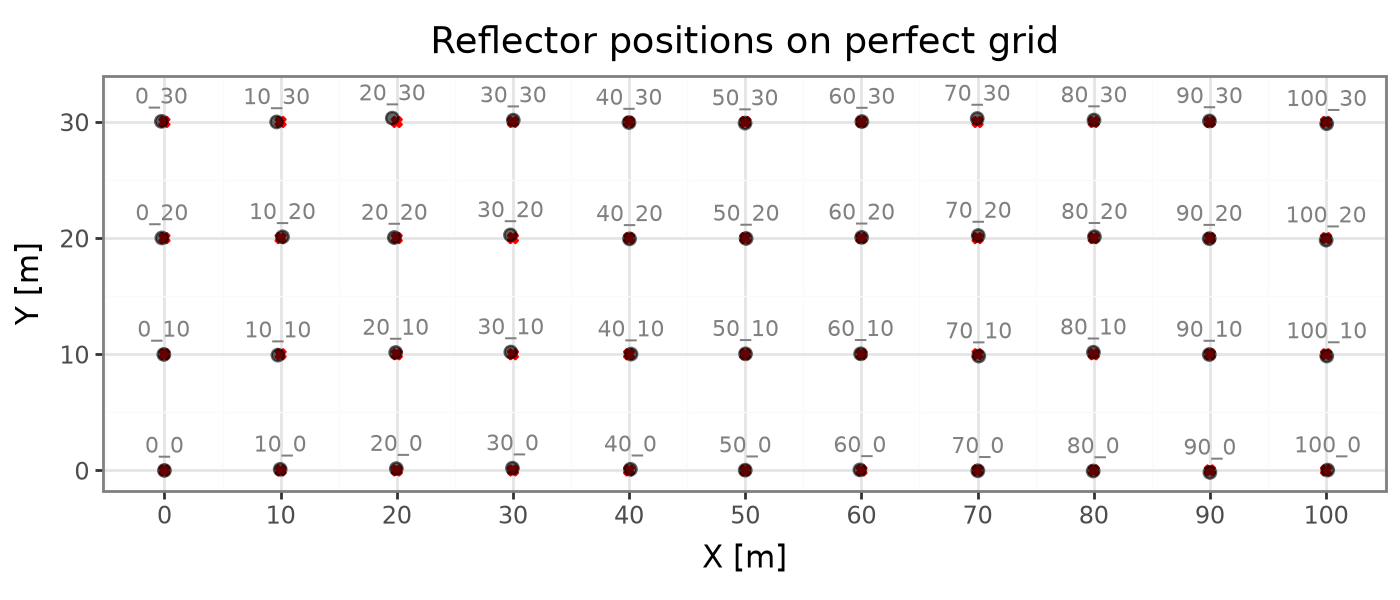

In [23]:
plot_refl(refl_df, point_kwargs={"alpha": 0.6}) + theme(figure_size=(7, 3))

# Analysis of distance

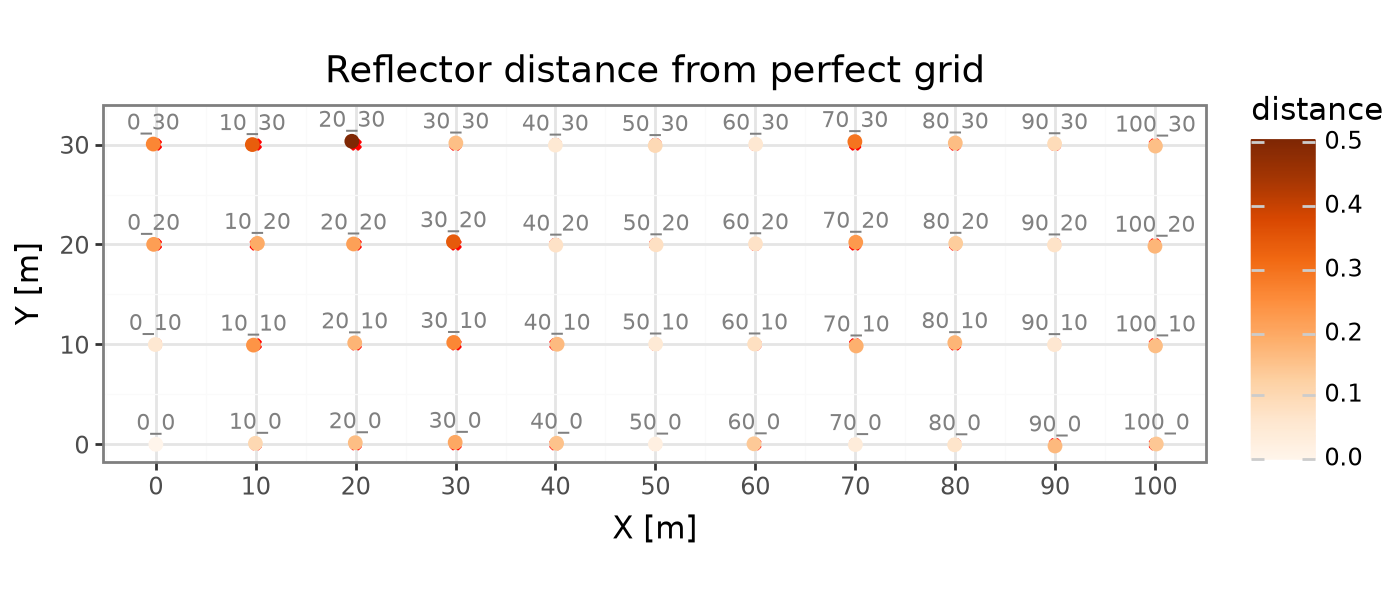

In [24]:
plot_refl(
    refl_df, point_extra_aes=aes(colour="distance"), point_kwargs={"alpha": 1}
) + theme(figure_size=(7, 3)
) + scale_color_cmap("Oranges") + labs(
    title = "Reflector distance from perfect grid"
)

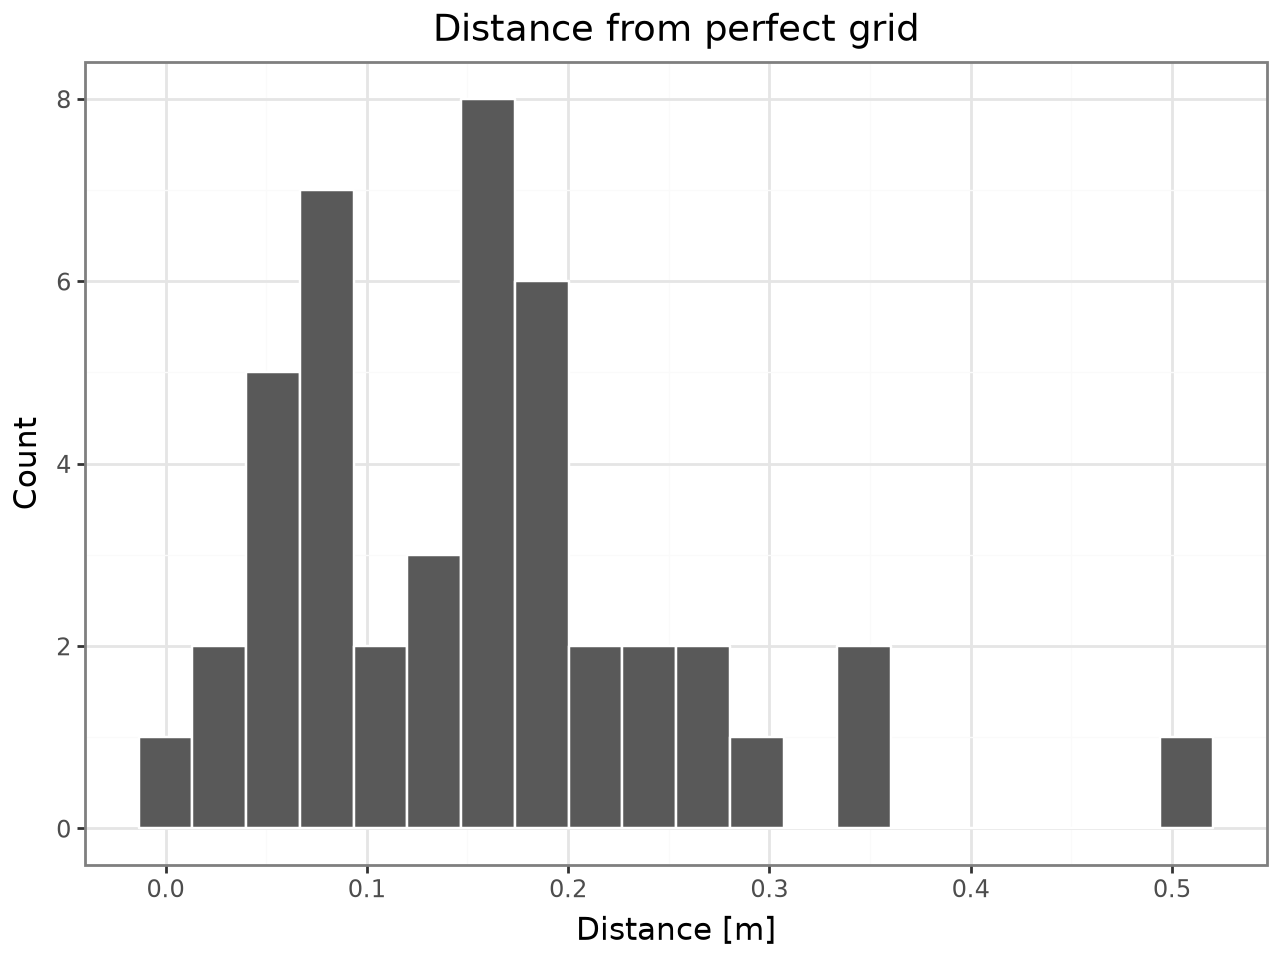

In [25]:
(
    ggplot(refl_df, aes(x="distance"))
    + geom_histogram(bins=20, color="white")
    + labs(
        title="Distance from perfect grid",
        x="Distance [m]",
        y="Count",
    )
)

In [26]:
dist_summary = refl_df.select(
    mean=c.distance.mean(),
    std=c.distance.std(),
    max=c.distance.max(),
    min=c.distance.min(),
    q50=c.distance.quantile(0.5),
    q90=c.distance.quantile(0.9),
    q95=c.distance.quantile(0.95)
)
dist_tbl = GT(dist_summary).tab_header(
    title="Summary distance from perfect grid",
).fmt_number(
    decimals=2
).tab_footnote(
    footnote="Distance are in meters"
)
dist_tbl

GT(_tbl_data=shape: (1, 7)
┌──────────┬──────────┬──────────┬─────┬─────────┬─────────┬──────────┐
│ mean     ┆ std      ┆ max      ┆ min ┆ q50     ┆ q90     ┆ q95      │
│ ---      ┆ ---      ┆ ---      ┆ --- ┆ ---     ┆ ---     ┆ ---      │
│ f64      ┆ f64      ┆ f64      ┆ f64 ┆ f64     ┆ f64     ┆ f64      │
╞══════════╪══════════╪══════════╪═════╪═════════╪═════════╪══════════╡
│ 0.155252 ┆ 0.099502 ┆ 0.507272 ┆ 0.0 ┆ 0.15912 ┆ 0.26599 ┆ 0.340971 │
└──────────┴──────────┴──────────┴─────┴─────────┴─────────┴──────────┘, _body=<great_tables._gt_data.Body object at 0x000001C4AFF316A0>, _boxhead=Boxhead([ColInfo(var='mean', type=<ColInfoTypeEnum.default: 1>, column_label='mean', column_align='right', column_width=None, stub_level=None), ColInfo(var='std', type=<ColInfoTypeEnum.default: 1>, column_label='std', column_align='right', column_width=None, stub_level=None), ColInfo(var='max', type=<ColInfoTypeEnum.default: 1>, column_label='max', column_align='right', column_width=None, stub_level=None), ColInfo(var='min', type=<ColInfoTypeEnum.default: 1>, column_label='min', column_align='right', column_width=None, stub_level=None), ColInfo(var='q50', type=<ColInfoTypeEnum.default: 1>, column_label='q50', column_align='right', column_width=None, stub_level=None), ColInfo(var='q90', type=<ColInfoTypeEnum.default: 1>, column_label='q90', column_align='right', column_width=None, stub_level=None), ColInfo(var='q95', type=<ColInfoTypeEnum.default: 1>, column_label='q95', column_align='right', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x000001C4AFF312B0>, _spanners=Spanners([]), _heading=Heading(title='Summary distance from perfect grid', subtitle=None, preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x000001C4AFF31A90>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x000001C4AFF1EE90>, _source_notes=[], _footnotes=[FootnoteInfo(locname=None, grpname=None, colname=None, rownum=None, colnum=None, footnotes=['Distance are in meters'], placement=<FootnotePlacement.auto: 3>)], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x000001C4AFF31BE0>, _formats=[<great_tables._gt_data.FormatInfo object at 0x000001C4AFF31940>], _substitutions=[], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_col

In [27]:
field_df = refl_df.select(
    c.label,
    c.x_corr * 100,  # convert to cm
    c.y_corr * 100,  # convert to cm
).drop_nulls()
field_table = (
    GT(field_df)
    .tab_header(
        title="Reflector position corrections (cm)",
    )
    .fmt_number(columns=["x_corr", "y_corr"], decimals=0)
    .tab_footnote(
        footnote=html("Shifts are in cm in plot coordinate system.<br> x positive -> east, y positive -> north.")
    ).opt_row_striping()
)

# Correction for the field

In [29]:
field_table.gtsave(here("reflector_field_corrections_part2.pdf"))

GT(_tbl_data=shape: (44, 3)
┌────────┬───────────┬───────────┐
│ label  ┆ x_corr    ┆ y_corr    │
│ ---    ┆ ---       ┆ ---       │
│ str    ┆ f64       ┆ f64       │
╞════════╪═══════════╪═══════════╡
│ 0_0    ┆ 0.0       ┆ 0.0       │
│ 0_10   ┆ 5.413226  ┆ 1.292556  │
│ 0_20   ┆ 22.022788 ┆ -1.272827 │
│ 0_30   ┆ 26.059989 ┆ -5.327679 │
│ 10_0   ┆ 3.491437  ┆ -9.762576 │
│ …      ┆ …         ┆ …         │
│ 90_30  ┆ 4.00042   ┆ -8.428499 │
│ 100_0  ┆ -14.01974 ┆ -3.057228 │
│ 100_10 ┆ -5.896898 ┆ 15.018267 │
│ 100_20 ┆ -0.54039  ┆ 17.526252 │
│ 100_30 ┆ -5.401803 ┆ 14.967028 │
└────────┴───────────┴───────────┘, _body=<great_tables._gt_data.Body object at 0x000001C4AF9C9810>, _boxhead=Boxhead([ColInfo(var='label', type=<ColInfoTypeEnum.default: 1>, column_label='label', column_align='left', column_width=None, stub_level=None), ColInfo(var='x_corr', type=<ColInfoTypeEnum.default: 1>, column_label='x_corr', column_align='right', column_width=None, stub_level=None), ColInfo(var='y_corr', type=<ColInfoTypeEnum.default: 1>, column_label='y_corr', column_align='right', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x000001C4AFF1F250>, _spanners=Spanners([]), _heading=Heading(title='Reflector position corrections (cm)', subtitle=None, preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x000001C4B0778410>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x000001C4AF9C8E90>, _source_notes=[], _footnotes=[FootnoteInfo(locname=None, grpname=None, colname=None, rownum=None, colnum=None, footnotes=['Shifts are in cm in plot coordinate system.<br> x positive -> east, y positive -> north.'], placement=<FootnotePlacement.auto: 3>)], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x000001C4B0778690>, _formats=[<great_tables._gt_data.FormatInfo object at 0x000001C4B0778A50>], _substitutions=[], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_right_style=OptionsInfo(scss=True, category='table', type='value', value='none'), table_border_right_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_right_color=OptionsInfo(scss=True, category='table', type='value', value='#D3D3D3'), 